In [1]:
%matplotlib widget

# Regions of Interest (ROIs)
A region of interest (ROI) is a selected portion of an image used for focused examination, measurement, or quantitative analysis.

This analysis uses a photograph of Group 4's microscopy display from the Spring 2026 laboratory session. The image is not the original fluorescence microscopy data.

In [2]:
# Numerical operations
import numpy as np

# Image loading and processing
from PIL import Image
from skimage import filters

# Visualization
import matplotlib.pyplot as plt
from matplotlib.widgets import RectangleSelector
from pathlib import Path

In [3]:
image_path = Path("../data/confocal immunofluorescence image.jpeg")
icc_image = np.array(Image.open(image_path).convert("RGB"))

print("ICC image shape: ", icc_image.shape)

ICC image shape:  (1440, 1920, 3)


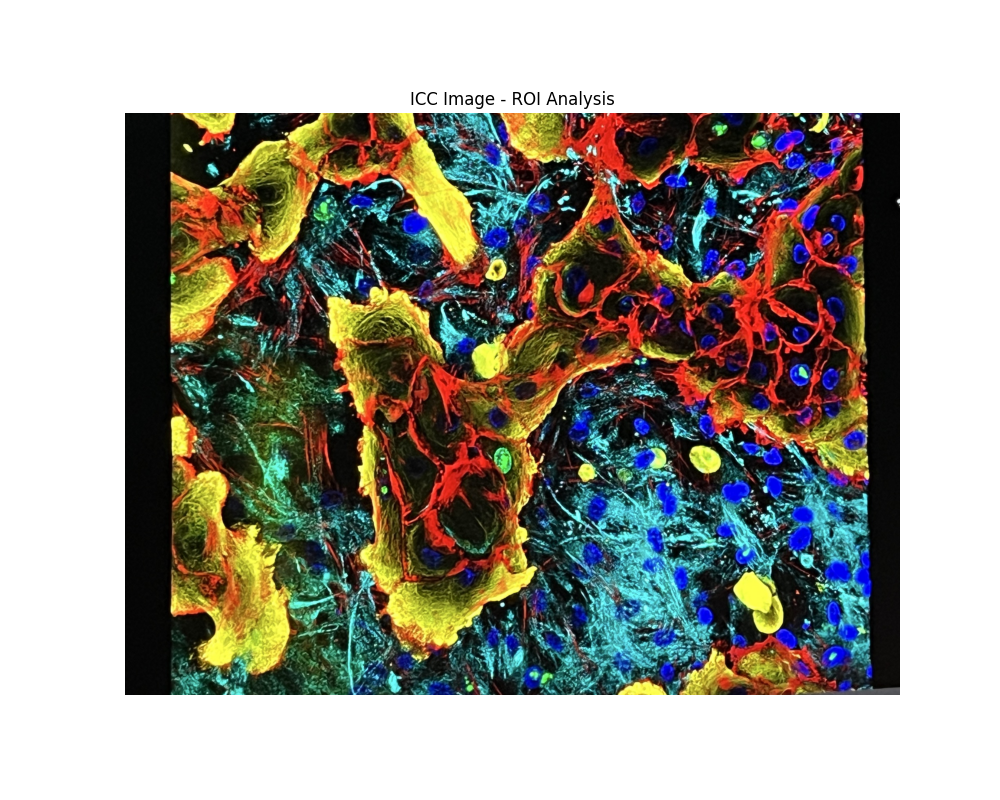

In [4]:
plt.figure(figsize=(10, 8))
plt.imshow(icc_image)
plt.title("ICC Image - ROI Analysis")
plt.axis("off")
plt.show()

In [5]:
# Define ROI boundaries
x1, x2 = 300, 600
y1, y2 = 250, 550

# Numpy uses [rows, columns]
# image arrays are indexed by rows first, then columns
roi = icc_image[y1:y2, x1:x2]

print("ROI shape: ", roi.shape)

ROI shape:  (300, 300, 3)


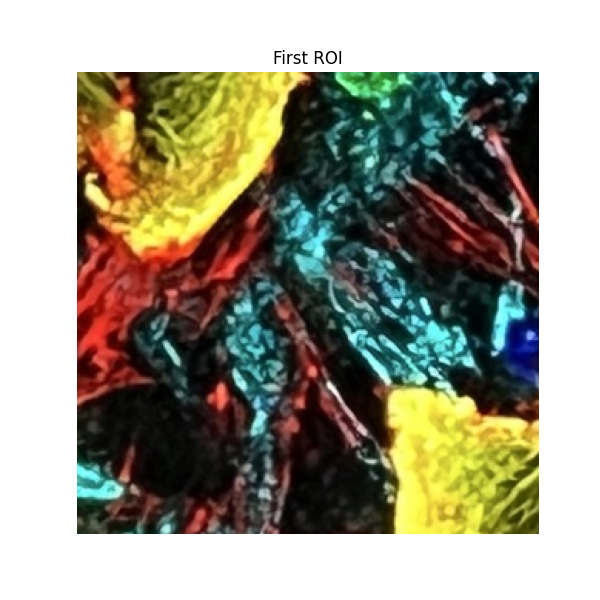

In [6]:
plt.figure(figsize=(6, 6))
plt.imshow(roi)
plt.title("First ROI")
plt.axis("off")
plt.show()

In [7]:
# Calculate the mean intensity for each RGB channel
# axis=(0, 1)m Nympy averages across the height and width dimensions
mean_rgb = roi.mean(axis=(0, 1)) 

print(f"Mean Red: {mean_rgb[0]:.2f}")
print(f"Mean Green: {mean_rgb[1]:.2f}")
print(f"Mean Blue: {mean_rgb[2]:.2f}")

Mean Red: 88.58
Mean Green: 84.31
Mean Blue: 55.03


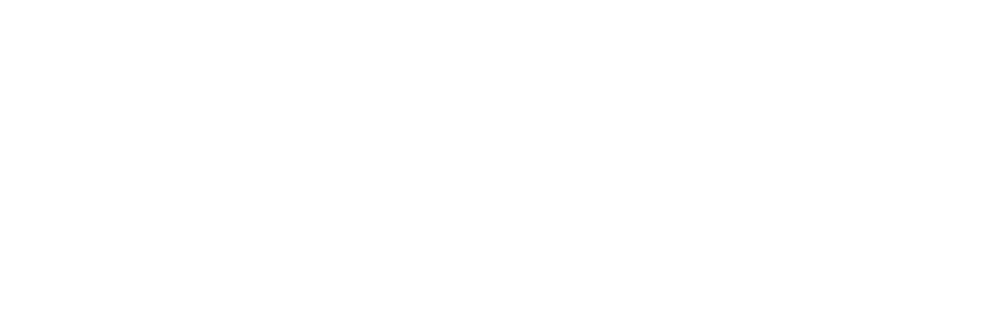

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

colors = ["Reds", "Greens", "Blues"]
titles = ["Red Channel", "Green Channel", "Blue Channel"]

for i in range(3):
    axes[i].imshow(roi[:, :, i], cmap=colors[i], vmin=0, vmax=255)
    axes[i].set_title(titles[i])
    axes[i].axis("off")

plt.tight_layout()
plt.show()

- Yellow structures are prominent in both the red and green channels.
- Cyan structures are prominent in both the green and blue channels.

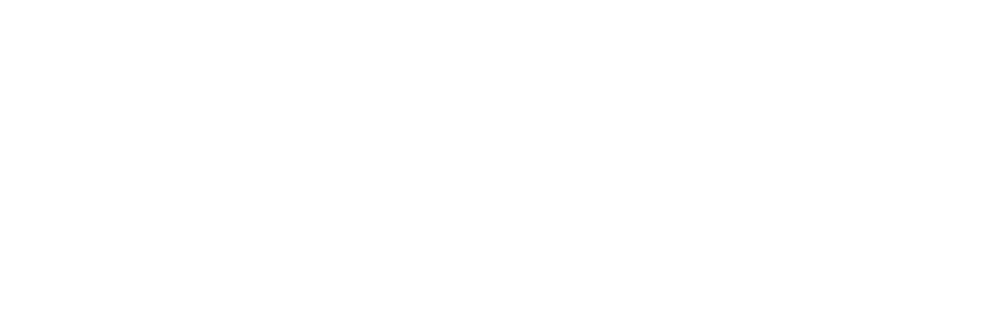

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

titles = ["Red Channel", "Green Channel", "Blue Channel"]

for i in range(3):
    axes[i].imshow(roi[:, :, i], cmap="gray", vmin=0, vmax=255)
    axes[i].set_title(titles[i])
    axes[i].axis("off")

plt.tight_layout()
plt.show()

The grayscale really shows this....
- Yellow structures are prominent in both the red and green channels.
- Cyan structures are prominent in both the green and blue channels.

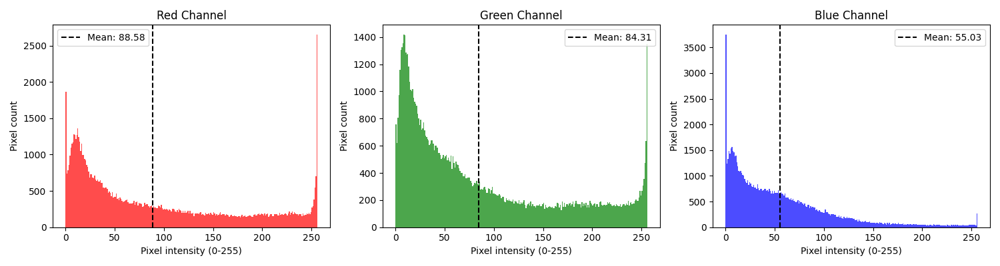

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

channels = ["Red", "Green", "Blue"]
colors = ["red", "green", "blue"]

for i in range(3):
    axes[i].hist(roi[:, :, i].ravel(), bins=256, range=(0, 256), color=colors[i], alpha=0.7)
    
    axes[i].axvline(mean_rgb[i], color="black", linestyle="--", label=f"Mean: {mean_rgb[i]:.2f}")

    axes[i].set_title(f"{channels[i]} Channel")
    axes[i].set_xlabel("Pixel intensity (0-255)")
    axes[i].set_ylabel("Pixel count")
    axes[i].legend()

plt.tight_layout()
plt.show()

In [11]:
for i, channel in enumerate(["Red", "Green", "Blue"]):
    values = roi[:, :, i]

    mean = np.mean(values)
    median = np.median(values)
    std = np.std(values)

    print(f"{channel} Channel")
    print(f" Mean:    {mean:.2f}")
    print(f" Median:  {median:.2f}")
    print(f" Std:     {std:.2f}")
    print()

Red Channel
 Mean:    88.58
 Median:  59.00
 Std:     80.72

Green Channel
 Mean:    84.31
 Median:  56.00
 Std:     77.54

Blue Channel
 Mean:    55.03
 Median:  41.00
 Std:     52.49



In [12]:
def on_select(eclick, erelease):
    # Coordinates where the mouse was pressed and released
    x1, y1 = eclick.xdata, eclick.ydata
    x2, y2 = erelease.xdata, erelease.ydata

    if None in (x1, y1, x2, y2):
        return

    # Sort coordinates so dragging works in any direction
    x_min, x_max = sorted([int(x1), int(x2)])
    y_min, y_max = sorted([int(y1), int(y2)])

    # Keep coordinates within image boundaries
    height, width = icc_image.shape[:2]
    x_min, x_max = max(0, x_min), min(width, x_max)
    y_min, y_max = max(0, y_min), min(height, y_max)

    roi = icc_image[y_min:y_max, x_min:x_max]

    if roi.size == 0:
        return

    selected_rois.append(roi.copy())

    print(f"ROI {len(selected_rois)} selected")
    print(f"Shape: {roi.shape}")
    print(f"Mean RGB: {roi.mean(axis=(0, 1)).round(2)}")

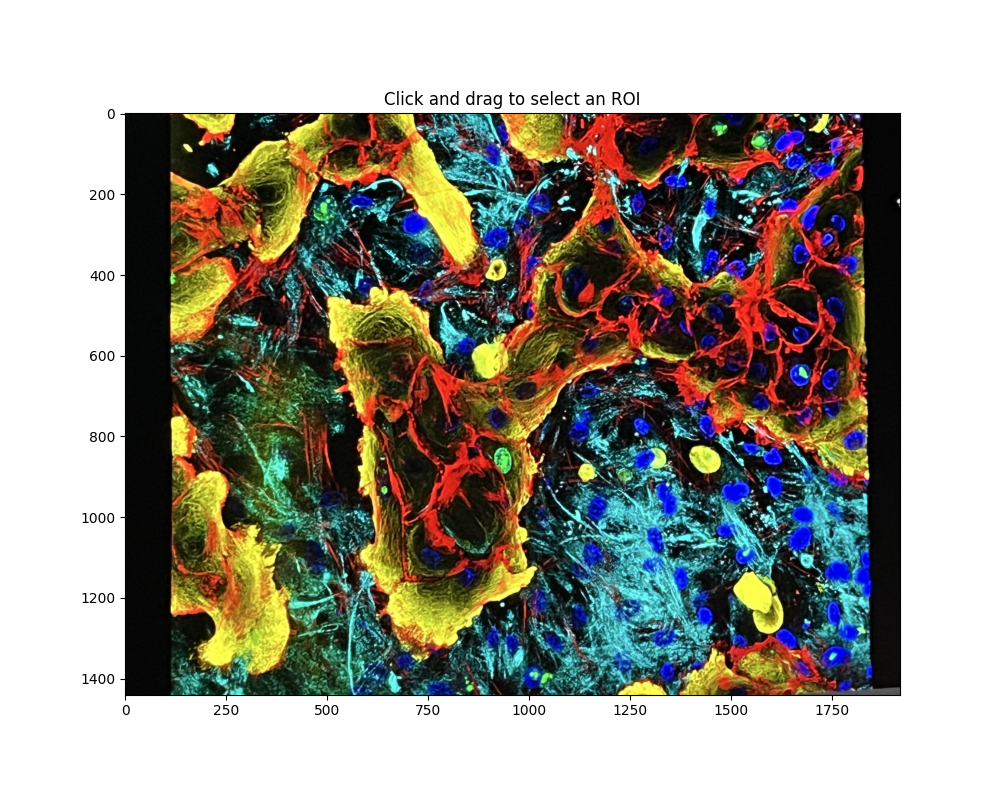

In [16]:
# Store selected ROIs
selected_rois = []

fig, ax = plt.subplots(figsize=(10, 8))

ax.imshow(icc_image)
ax.set_title("Click and drag to select an ROI")

selector = RectangleSelector(ax, on_select, useblit=False, button=[1], minspanx=5, minspany=5, spancoords="pixels", interactive=True)

plt.show()
    

In [17]:
if selected_rois:
    selected_rois.clear()

In [18]:
for i, roi_data in enumerate(selected_rois[:2], start=1):
    print(f"ROI {i}")
    print("Shape: ", roi_data.shape)
    print("Mean RGB: ", roi_data.mean(axis=(0, 1)).round(2))
    print("Median RGB: ", np.median(roi_data, axis=(0, 1)).round(2))
    print(f"Std RGB: {roi_data.std(axis=(0, 1)).round(2)}\n")

ROI 1
Shape:  (47, 52, 3)
Mean RGB:  [252.1  254.45  77.31]
Median RGB:  [254. 255.  76.]
Std RGB: [5.76 1.65 5.5 ]

ROI 2
Shape:  (42, 52, 3)
Mean RGB:  [ 73.06 181.37 188.53]
Median RGB:  [ 71. 182. 191.]
Std RGB: [27.27 44.05 45.35]



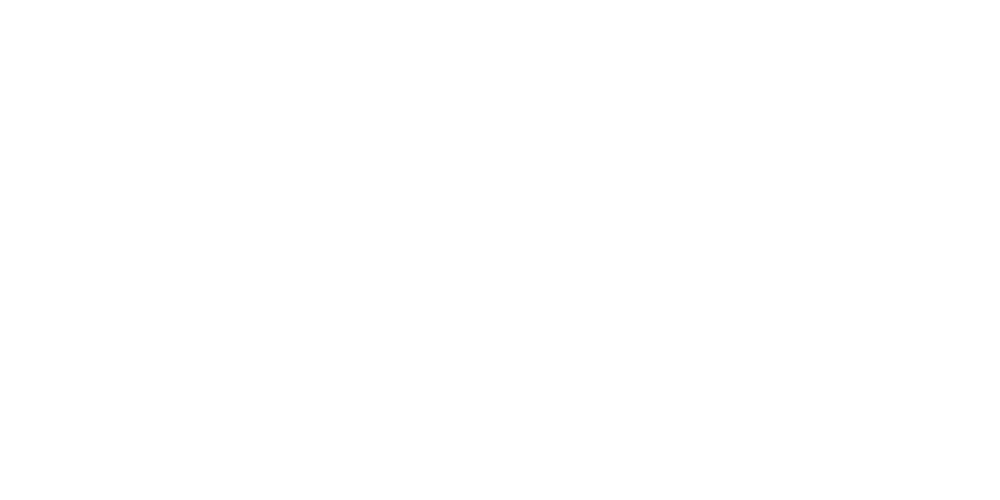

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for i, roi_data in enumerate(selected_rois[:2]):
    axes[i].imshow(roi_data)
    axes[i].set_title(f"ROI {i + 1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [20]:
from matplotlib.widgets import PolygonSelector
from matplotlib.path import Path

In [21]:
polygon_rois = []

In [22]:
def on_polygon_select(vertices):
    height, width = icc_image.shape[:2]

    # Create a grid of pixel coordinates
    yy, xx = np.mgrid[:height, :width]

    # Convert the grid into coordinate pairs
    points = np.column_stack((xx.ravel(), yy.ravel()))

    # Determine which pixel centers fall inside the polygon
    path = Path(vertices)
    mask = path.contains_points(points).reshape(height, width)

    # Extract only the selected RGB pixels
    pixels = icc_image[mask]

    if pixels.size == 0:
        print("No pixels selected.")
        return

    # Ignore polygons whose masks have already been saved
    if any(np.array_equal(mask, saved["mask"]) for saved in polygon_rois):
        print("Duplicate polygon ignored.")
        return

    polygon_rois.append({
        "vertices": np.array(vertices).copy(),
        "mask": mask.copy(),
        "pixels": pixels.copy()
    })

    print(f"Polygon ROI: {len(polygon_rois)}")
    print("Selected pixels: ", len(pixels))
    print("Mean RGB: ", pixels.mean(axis=0).round(2))
    print("Median RGB: ", np.median(pixels, axis=0).round(2))
    print("Std RGB: ", pixels.std(axis=0).round(2))
    

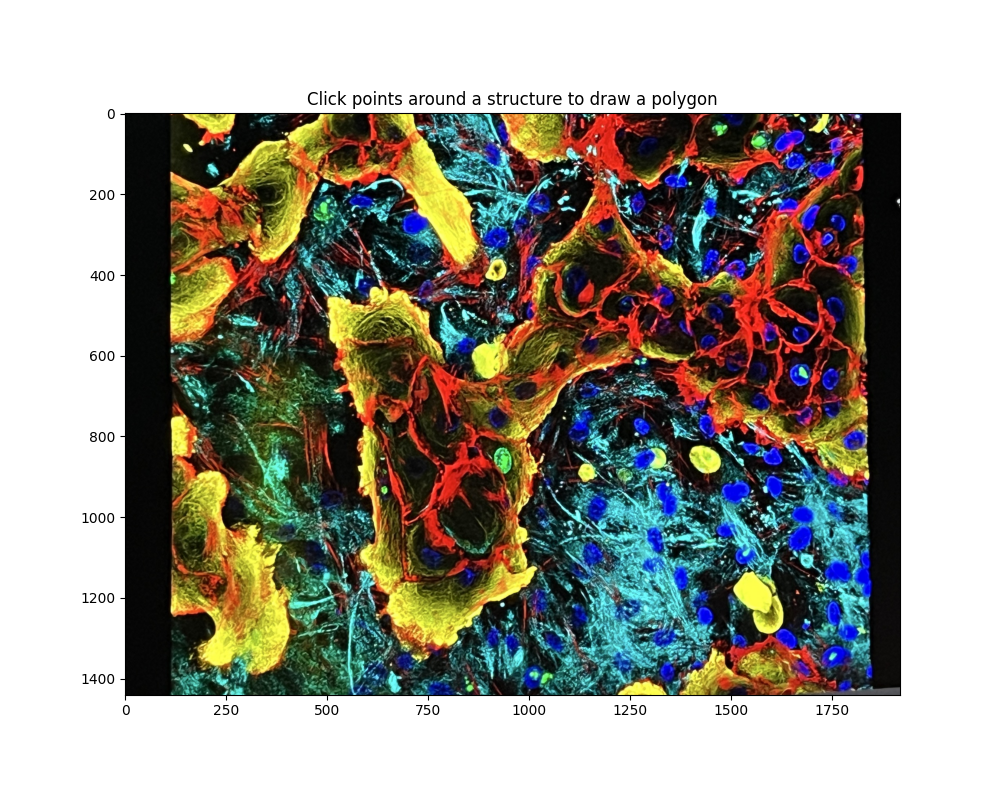

In [23]:
fig, ax = plt.subplots(figsize=(10, 8))

ax.imshow(icc_image)
ax.set_title("Click points around a structure to draw a polygon")

polygon_selector = PolygonSelector(ax, on_polygon_select, useblit=False)

plt.show()


In [24]:
print("Saved polygons:", len(polygon_rois))

Saved polygons: 2


In [25]:
print("Total saved ROIs: ", len(polygon_rois))

for i, roi in enumerate(polygon_rois, start=1):
    print(
        f"ROI {i}: "
        f"{len(roi['vertices'])} vertices, "
        f"{len(roi['pixels'])} pixels, "
    )

Total saved ROIs:  2
ROI 1: 4 vertices, 888 pixels, 
ROI 2: 5 vertices, 326 pixels, 


In [26]:
for i in range(1, len(polygon_rois)):
    identical = np.array_equal(polygon_rois[i - 1]["mask"], polygon_rois[i]["mask"])

    print(f"ROI {i} vs ROI {i + 1}: {identical}")


ROI 1 vs ROI 2: False


In [27]:
for i, roi in enumerate(polygon_rois, start=1):
    pixels = roi["pixels"]

    print(f"Polygon ROI {i}")
    print(f"Pixels: {len(pixels)}")
    print(f"Mean RGB: {pixels.mean(axis=0).round(2)}")
    print(f"Median RGB: {np.median(pixels, axis=0).round(2)}")
    print(f"Std RGB: {pixels.std(axis=0).round(2)}\n")

Polygon ROI 1
Pixels: 888
Mean RGB: [253.93 254.87  75.91]
Median RGB: [254. 255.  76.]
Std RGB: [0.72 0.4  0.69]

Polygon ROI 2
Pixels: 326
Mean RGB: [ 96.44 229.11 231.53]
Median RGB: [102.  237.  239.5]
Std RGB: [16.75 24.13 23.32]



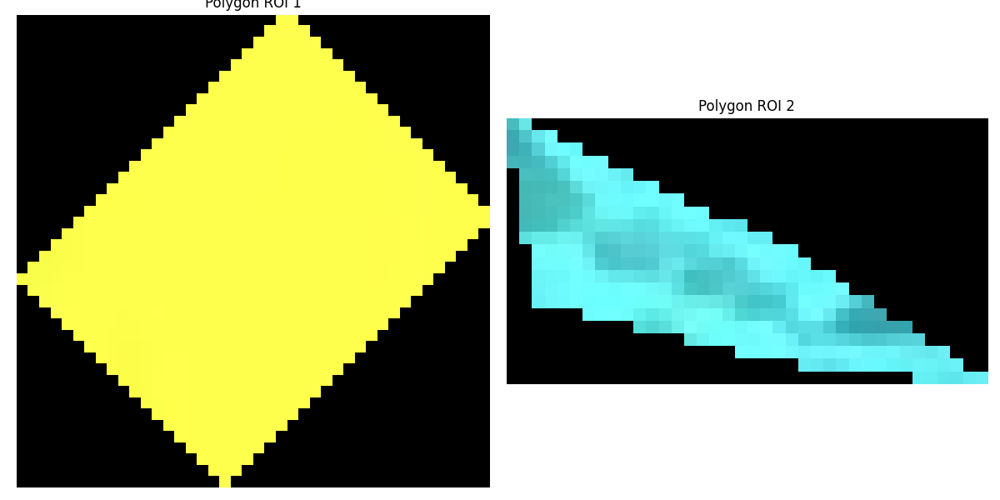

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for i, roi in enumerate(polygon_rois[:2]):

    mask = roi["mask"]

    y, x = np.where(mask)

    y_min, y_max = y.min(), y.max() + 1
    x_min, x_max = x.min(), x.max() + 1

    cropped_image = icc_image[y_min:y_max, x_min:x_max]
    cropped_mask = mask[y_min:y_max, x_min:x_max]

    cropped_roi = np.zeros_like(cropped_image)
    cropped_roi[cropped_mask] = cropped_image[cropped_mask]
    
    axes[i].imshow(cropped_roi, interpolation="nearest")
    axes[i].set_title(f"Polygon ROI {i + 1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()